# Notebook Eksperimen: 3 Kelas Tersusah

<table>
  <tr><td><b>Nama</b></td><td>Shabrina Sarayati</td></tr>
  <tr><td><b>NRP</b></td><td>5054241009</td></tr>
  <tr><td><b>Mata Kuliah</b></td><td>Visi Komputer</td></tr>
</table>


## A: Ekstrak `custom_test_set.zip` & Dataset Asli

In [ ]:
# A1. Install library yang dibutuhkan
!pip install -q roboflow ultralytics transformers accelerate pycocotools pyyaml pandas matplotlib

In [ ]:
# A2. Mount Google Drive, Ekstrak custom_test_set.zip
import os
import gc
import json
import time
import shutil
import random
import zipfile
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter
from torchvision.transforms import functional as F
import torchvision
from torchvision.models.detection.mask_rcnn import MaskRCNN_ResNet50_FPN_V2_Weights, MaskRCNNPredictor
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from pycocotools.coco import COCO
from pycocotools import mask as mask_utils
from pycocotools.cocoeval import COCOeval
from google.colab import drive

drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/Visi Komputer/Tugas2"
ALL_CLS_DIR = os.path.join(BASE_DIR, "baseline_all_classes")
OUT_DIR = os.path.join(BASE_DIR, "tahap2_3kelas_dan_domain_shift")
VIZ_DIR = os.path.join(OUT_DIR, "visualizations")
FAIL_DIR = os.path.join(OUT_DIR, "failure_analysis")
for d in [OUT_DIR, VIZ_DIR, FAIL_DIR]:
    os.makedirs(d, exist_ok=True)

# 3 Kelas Tersulit (urut alfabet agar ID konsisten: YOLO 0,1,2 | COCO 1,2,3)
HARD_CLASSES = ["cabinet-merged", "pillow", "wall-tile"]

# Ekstrak custom_test_set.zip dari Drive ke /content/custom_test_set
CUSTOM_ZIP = os.path.join(BASE_DIR, "custom_test_set.zip")
CUSTOM_DIR = "/content/custom_test_set"
assert os.path.exists(CUSTOM_ZIP), f"File tidak ditemukan: {CUSTOM_ZIP}"
if os.path.exists(CUSTOM_DIR):
    shutil.rmtree(CUSTOM_DIR)
with zipfile.ZipFile(CUSTOM_ZIP, "r") as zf:
    zf.extractall(CUSTOM_DIR)

# Perbaiki path data.yaml milik custom_test_set/yolo
custom_yolo_yaml = os.path.join(CUSTOM_DIR, "yolo", "data.yaml")
with open(custom_yolo_yaml, "r") as f:
    cy_cfg = yaml.safe_load(f)
cy_cfg["path"] = os.path.join(CUSTOM_DIR, "yolo")
cy_cfg["train"] = "images"
cy_cfg["val"] = "images"
cy_cfg["test"] = "images"
with open(custom_yolo_yaml, "w") as f:
    yaml.safe_dump(cy_cfg, f, sort_keys=False)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def load_coco_aligned_image(img_path, info):
    img = Image.open(img_path)
    expected_size = (int(info["width"]), int(info["height"]))
    if img.size == expected_size:
        return img.convert("RGB")
    img_t = ImageOps.exif_transpose(img)
    if img_t.size == expected_size:
        return img_t.convert("RGB")
    return img_t.convert("RGB").resize(expected_size, Image.BILINEAR)

def compute_coco_metrics(coco_gt, coco_results):
    if len(coco_results) == 0:
        return {"mask_mAP50_95": 0.0, "mask_mAP50": 0.0}, pd.DataFrame()
    coco_dt = coco_gt.loadRes(coco_results)
    coco_eval = COCOeval(coco_gt, coco_dt, iouType="segm")
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()
    stats = {
        "mask_mAP50_95": round(float(coco_eval.stats[0]), 4),
        "mask_mAP50": round(float(coco_eval.stats[1]), 4),
    }
    precision = coco_eval.eval["precision"]
    rows = []
    for k, cid in enumerate(coco_eval.params.catIds):
        cname = coco_gt.cats[cid]["name"]
        p_all = precision[:, :, k, 0, 2]
        p_50 = precision[0, :, k, 0, 2]
        ap50_95 = float(np.mean(p_all[p_all > -1])) if np.any(p_all > -1) else np.nan
        ap50 = float(np.mean(p_50[p_50 > -1])) if np.any(p_50 > -1) else np.nan
        n_gt = len(coco_gt.getAnnIds(catIds=[cid]))
        rows.append({
            "class_id": int(cid),
            "class_name": cname,
            "gt_instances": int(n_gt),
            "mask_ap50": round(ap50, 4) if not np.isnan(ap50) else np.nan,
            "mask_ap50_95": round(ap50_95, 4) if not np.isnan(ap50_95) else np.nan,
        })
    return stats, pd.DataFrame(rows).sort_values("mask_ap50_95")

class CocoInstanceDataset(Dataset):
    def __init__(self, split_dir, cat_ids=None, filter_empty=False):
        self.split_dir = split_dir
        self.coco = COCO(os.path.join(split_dir, "_annotations.coco.json"))
        self.cat_ids = sorted(self.coco.getCatIds()) if cat_ids is None else cat_ids
        self.cat2label = {cid: i + 1 for i, cid in enumerate(self.cat_ids)}
        self.label2cat = {i + 1: cid for i, cid in enumerate(self.cat_ids)}
        all_img_ids = sorted(self.coco.getImgIds())
        if filter_empty:
            self.img_ids = [i for i in all_img_ids if len(self._extract_valid_anns(i)[0]) > 0]
        else:
            self.img_ids = all_img_ids

    def _extract_valid_anns(self, img_id):
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=img_id))
        info = self.coco.loadImgs(img_id)[0]
        h_exp, w_exp = int(info["height"]), int(info["width"])
        boxes, labels, masks = [], [], []
        for ann in anns:
            if ann.get("iscrowd", 0) != 0 or ann["category_id"] not in self.cat2label:
                continue
            try:
                m = self.coco.annToMask(ann)
            except Exception:
                continue
            if m.shape != (h_exp, w_exp):
                continue
            pos = np.where(m > 0)
            if len(pos[0]) == 0:
                continue
            ymin, ymax = int(np.min(pos[0])), int(np.max(pos[0]))
            xmin, xmax = int(np.min(pos[1])), int(np.max(pos[1]))
            if xmax <= xmin or ymax <= ymin:
                continue
            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(self.cat2label[ann["category_id"]])
            masks.append(m.astype(np.uint8))
        return boxes, labels, masks

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        info = self.coco.loadImgs(img_id)[0]
        img = load_coco_aligned_image(os.path.join(self.split_dir, info["file_name"]), info)
        img_t = F.to_tensor(img)
        boxes, labels, masks = self._extract_valid_anns(img_id)
        if len(boxes) == 0:
            target = {
                "boxes": torch.zeros((0, 4), dtype=torch.float32),
                "labels": torch.zeros((0,), dtype=torch.int64),
                "masks": torch.zeros((0, img_t.shape[1], img_t.shape[2]), dtype=torch.uint8),
                "image_id": torch.tensor([img_id]),
            }
        else:
            target = {
                "boxes": torch.as_tensor(boxes, dtype=torch.float32),
                "labels": torch.as_tensor(labels, dtype=torch.int64),
                "masks": torch.as_tensor(np.stack(masks, axis=0), dtype=torch.uint8),
                "image_id": torch.tensor([img_id]),
            }
        return img_t, target

def mrcnn_collate(batch):
    return tuple(zip(*batch))

@torch.no_grad()
def eval_mrcnn(model, loader, ds, score_thresh=0.05, max_eval_side=1333):
    model.eval()
    coco_results = []
    for images, targets in loader:
        for img_t, t in zip(images, targets):
            img_id = int(t["image_id"].item())
            orig_h, orig_w = img_t.shape[1], img_t.shape[2]
            scale = min(1.0, max_eval_side / float(max(orig_h, orig_w)))
            if scale < 1.0:
                new_h, new_w = int(round(orig_h * scale)), int(round(orig_w * scale))
                img_in = torch.nn.functional.interpolate(
                    img_t.unsqueeze(0), size=(new_h, new_w), mode="bilinear", align_corners=False
                ).squeeze(0)
            else:
                img_in = img_t

            out = model([img_in.to(device)])[0]
            scores = out["scores"].cpu().numpy()
            labels = out["labels"].cpu().numpy()
            masks = out["masks"].cpu().numpy()
            del out
            for sc, lb, mk in zip(scores, labels, masks):
                if sc < score_thresh or int(lb) not in ds.label2cat:
                    continue
                bm = (mk[0] > 0.5).astype(np.uint8)
                if bm.sum() == 0:
                    continue
                if bm.shape != (orig_h, orig_w):
                    bm = (np.array(Image.fromarray(bm * 255).resize((orig_w, orig_h), Image.NEAREST)) > 127).astype(np.uint8)
                rle = mask_utils.encode(np.asfortranarray(bm))
                rle["counts"] = rle["counts"].decode("utf-8")
                coco_results.append({
                    "image_id": img_id,
                    "category_id": int(ds.label2cat[int(lb)]),
                    "segmentation": rle,
                    "score": float(sc),
                })
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return compute_coco_metrics(ds.coco, coco_results)

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("PyTorch:", torch.__version__, "| Device:", device, f"({gpu_name})")
print("Custom test set extracted to:", CUSTOM_DIR)
print("Output directory:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.14.1+cu130 | Device: cuda (Tesla T4)
Custom test set extracted to: /content/custom_test_set
Output directory: /content/drive/MyDrive/Visi Komputer/Tugas2/tahap2_3kelas_dan_domain_shift


In [ ]:
# A3. Download Dataset Asli Panoptic Indoor Segmentation
from getpass import getpass
from roboflow import Roboflow

YOLO_ORIG_DIR = "/content/dataset_yolov8"
COCO_ORIG_DIR = "/content/dataset_coco"

if not (os.path.exists(os.path.join(YOLO_ORIG_DIR, "data.yaml")) and os.path.exists(os.path.join(COCO_ORIG_DIR, "train", "_annotations.coco.json"))):
    ROBOFLOW_API_KEY = getpass("Masukkan Roboflow API Key: ")
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    version = rf.workspace("panopticindoor").project("panoptic-indoor-segmentation").version(5)
    version.download("yolov8", location=YOLO_ORIG_DIR)
    version.download("coco-segmentation", location=COCO_ORIG_DIR)

# Perbaiki path data.yaml dataset asli
orig_yolo_yaml = os.path.join(YOLO_ORIG_DIR, "data.yaml")
with open(orig_yolo_yaml, "r") as f:
    oy_cfg = yaml.safe_load(f)
oy_cfg["path"] = YOLO_ORIG_DIR
oy_cfg["train"] = "train/images"
oy_cfg["val"] = "valid/images"
oy_cfg["test"] = "test/images"
with open(orig_yolo_yaml, "w") as f:
    yaml.safe_dump(oy_cfg, f, sort_keys=False)

print("Dataset asli siap:", YOLO_ORIG_DIR, "|", COCO_ORIG_DIR)

Dataset asli siap: /content/dataset_yolov8 | /content/dataset_coco


## B: Evaluasi 3 Model "Semua Kelas" pada 44 Foto `custom_test_set`

In [ ]:
# B1. Evaluasi YOLOv8s-seg, Mask R-CNN, dan Mask2Former (Model Semua Kelas) pada Custom Test Set
from ultralytics import YOLO
from transformers import Mask2FormerImageProcessor, Mask2FormerForUniversalSegmentation

DS_DIR = os.path.join(OUT_DIR, "domain_shift_all_classes")
os.makedirs(DS_DIR, exist_ok=True)

custom_all_summary = []

# 1) YOLOv8s-seg (All Classes) -> Custom Test Set
print("[1/3] Evaluasi YOLOv8s-seg (Semua Kelas) di Custom Test Set ")
yolo_all = YOLO(os.path.join(ALL_CLS_DIR, "01_yolov8s_seg", "train", "weights", "best.pt"))
m_yolo_custom = yolo_all.val(
    data=custom_yolo_yaml,
    split="test",
    imgsz=640,
    project=DS_DIR,
    name="yolo_custom_eval",
    exist_ok=True,
)
custom_all_summary.append({
    "model": "YOLOv8s-seg",
    "split": "custom_test",
    "mask_mAP50": round(float(m_yolo_custom.seg.map50), 4),
    "mask_mAP50_95": round(float(m_yolo_custom.seg.map), 4),
})
y_rows = []
for idx, cid in enumerate(m_yolo_custom.seg.ap_class_index):
    y_rows.append({
        "class_id": int(cid),
        "class_name": yolo_all.names[int(cid)],
        "mask_ap50": round(float(m_yolo_custom.seg.ap50[idx]), 4),
        "mask_ap50_95": round(float(m_yolo_custom.seg.ap[idx]), 4),
    })
df_y_custom = pd.DataFrame(y_rows).sort_values("mask_ap50_95")
df_y_custom.to_csv(os.path.join(DS_DIR, "per_class_ap_yolo_custom.csv"), index=False)
del yolo_all
free_gpu()

# 2) Mask R-CNN (All Classes) -> Custom Test Set
print("\n[2/3] Evaluasi Mask R-CNN (Semua Kelas) di Custom Test Set ")
coco_custom_dir = os.path.join(CUSTOM_DIR, "coco")
mr_custom_ds = CocoInstanceDataset(coco_custom_dir)
mr_custom_loader = DataLoader(mr_custom_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=mrcnn_collate)

num_classes_all = len(mr_custom_ds.cat_ids) + 1  # 75 + 1 = 76
mr_all = torchvision.models.detection.maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None)
mr_all.roi_heads.box_predictor = FastRCNNPredictor(mr_all.roi_heads.box_predictor.cls_score.in_features, num_classes_all)
mr_all.roi_heads.mask_predictor = MaskRCNNPredictor(mr_all.roi_heads.mask_predictor.conv5_mask.in_channels, 256, num_classes_all)
mr_all.load_state_dict(torch.load(os.path.join(ALL_CLS_DIR, "02_maskrcnn", "best_maskrcnn.pth"), map_location=device))
mr_all.to(device).eval()

st_mr_c, df_mr_custom = eval_mrcnn(mr_all, mr_custom_loader, mr_custom_ds)
custom_all_summary.append({"model": "Mask R-CNN", "split": "custom_test", **st_mr_c})
df_mr_custom.to_csv(os.path.join(DS_DIR, "per_class_ap_mrcnn_custom.csv"), index=False)
del mr_all
free_gpu()

# 3) Mask2Former (All Classes) -> Custom Test Set
print("\n[3/3] Evaluasi Mask2Former (Semua Kelas) di Custom Test Set ")
m2f_all_dir = os.path.join(ALL_CLS_DIR, "03_mask2former", "best_mask2former")
m2f_all_proc = Mask2FormerImageProcessor.from_pretrained(m2f_all_dir)
m2f_all = Mask2FormerForUniversalSegmentation.from_pretrained(m2f_all_dir).to(device).eval()

coco_custom = COCO(os.path.join(coco_custom_dir, "_annotations.coco.json"))
cat_ids_all = sorted(coco_custom.getCatIds())
label2cat_all = {i: cid for i, cid in enumerate(cat_ids_all)}

m2f_custom_results = []
with torch.no_grad():
    for iid in sorted(coco_custom.getImgIds()):
        info = coco_custom.loadImgs(iid)[0]
        img_pil = load_coco_aligned_image(os.path.join(coco_custom_dir, info["file_name"]), info)
        w, h = img_pil.size
        scale = min(1.0, 1024.0 / float(max(w, h)))
        hs, ws = int(round(h * scale)), int(round(w * scale))
        inp = m2f_all_proc(images=[img_pil], return_tensors="pt")
        out = m2f_all(pixel_values=inp["pixel_values"].to(device), pixel_mask=inp["pixel_mask"].to(device))
        res = m2f_all_proc.post_process_instance_segmentation(out, threshold=0.3, target_sizes=[(hs, ws)])[0]
        seg = res["segmentation"].cpu().numpy()
        seg_infos = res["segments_info"]
        del out, res
        for sinfo in seg_infos:
            lbl = int(sinfo["label_id"])
            if lbl not in label2cat_all:
                continue
            bm = (seg == sinfo["id"]).astype(np.uint8)
            if bm.sum() == 0:
                continue
            if bm.shape != (h, w):
                bm = (np.array(Image.fromarray(bm * 255).resize((w, h), Image.NEAREST)) > 127).astype(np.uint8)
            rle = mask_utils.encode(np.asfortranarray(bm))
            rle["counts"] = rle["counts"].decode("utf-8")
            m2f_custom_results.append({
                "image_id": int(iid),
                "category_id": int(label2cat_all[lbl]),
                "segmentation": rle,
                "score": float(sinfo["score"]),
            })
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

st_m2f_c, df_m2f_custom = compute_coco_metrics(coco_custom, m2f_custom_results)
custom_all_summary.append({"model": "Mask2Former", "split": "custom_test", **st_m2f_c})
df_m2f_custom.to_csv(os.path.join(DS_DIR, "per_class_ap_m2f_custom.csv"), index=False)
del m2f_all
free_gpu()

# Bandingkan Test Set Asli vs Custom Test Set (Domain Shift)
orig_sum_files = [
    os.path.join(ALL_CLS_DIR, "01_yolov8s_seg", "eval_summary.csv"),
    os.path.join(ALL_CLS_DIR, "02_maskrcnn", "eval_summary.csv"),
    os.path.join(ALL_CLS_DIR, "03_mask2former", "eval_summary.csv"),
]
df_orig = pd.concat([pd.read_csv(f) for f in orig_sum_files], ignore_index=True)
df_orig_test = df_orig[df_orig["split"] == "test"].copy()
df_custom_test = pd.DataFrame(custom_all_summary)

df_ds = df_orig_test.merge(
    df_custom_test, on="model", suffixes=("_orig_test", "_custom_test")
)
df_ds["delta_mAP50"] = (df_ds["mask_mAP50_custom_test"] - df_ds["mask_mAP50_orig_test"]).round(4)
df_ds["delta_mAP50_95"] = (df_ds["mask_mAP50_95_custom_test"] - df_ds["mask_mAP50_95_orig_test"]).round(4)
df_ds.to_csv(os.path.join(DS_DIR, "domain_shift_all_classes.csv"), index=False)

print("\nTABEL DOMAIN SHIFT (MODEL SEMUA KELAS: TEST ASLI VS CUSTOM TEST 44 FOTO) ")
print(df_ds[["model", "mask_mAP50_orig_test", "mask_mAP50_custom_test", "delta_mAP50",
             "mask_mAP50_95_orig_test", "mask_mAP50_95_custom_test", "delta_mAP50_95"]].to_string(index=False))

[1/3] Evaluasi YOLOv8s-seg (Semua Kelas) di Custom Test Set 
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-seg summary (fused): 85 layers, 11,808,238 parameters, 0 gradients, 40.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2626.5±1488.7 MB/s, size: 814.5 KB)
val: Scanning /content/custom_test_set/yolo/labels... 44 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 292.1it/s 0.2s
val: New cache created: /content/custom_test_set/yolo/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.7s/it 8.2s
                   all         44        381      0.561      0.301       0.33      0.249       0.48      0.339      0.318      0.228
                   bed          7         14      0.545      0.429      0.391      0.339      0.567        0.5      0.459      0.322
               blanket          2          4     

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.03s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.24s).
Accumulating evaluation results...
DONE (t=0.11s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.155
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.201
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.163
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.158
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.179
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.212
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets

## C: Filter "Hanya 3 Kelas Tersulit"
Memfilter dataset (`train` hanya mengambil 51 gambar yang memuat ≥ 1 dari `cabinet-merged`, `pillow`, `wall-tile` agar seragam & bebas *empty-batch* di ketiga model), sedangkan pada `valid` (166 foto), `test` asli (359 foto), dan `custom_test` (44 foto), **semua gambar tetap dipertahankan** dengan anotasi hanya 3 kelas tersebut agar *false positive* tetap terukur adil.

In [ ]:
# C1. Filter Dataset COCO & YOLO ke 3 Kelas Tersulit: cabinet-merged, pillow, wall-tile
COCO_3CLS_DIR = "/content/dataset_coco_3cls"
YOLO_3CLS_DIR = "/content/dataset_yolo_3cls"
CUSTOM_3CLS_COCO = "/content/custom_test_set_3cls/coco"
CUSTOM_3CLS_YOLO = "/content/custom_test_set_3cls/yolo"

for d in [COCO_3CLS_DIR, YOLO_3CLS_DIR, CUSTOM_3CLS_COCO, CUSTOM_3CLS_YOLO]:
    if os.path.exists(d):
        shutil.rmtree(d)

NEW_CATS_COCO = [
    {"id": idx + 1, "name": cname, "supercategory": "indoor-objects"}
    for idx, cname in enumerate(HARD_CLASSES)
]
NAME_TO_NEW_COCO_ID = {c["name"]: c["id"] for c in NEW_CATS_COCO}
NAME_TO_NEW_YOLO_ID = {cname: idx for idx, cname in enumerate(HARD_CLASSES)}

def link_or_copy(src, dst):
    if os.path.exists(dst):
        return
    try:
        os.symlink(src, dst)
    except Exception:
        shutil.copy2(src, dst)

def filter_coco_split(src_dir, dst_dir, keep_only_positive=False):
    os.makedirs(dst_dir, exist_ok=True)
    with open(os.path.join(src_dir, "_annotations.coco.json"), "r") as f:
        data = json.load(f)
    old_id2name = {c["id"]: c["name"] for c in data["categories"]}

    filtered_anns = []
    pos_img_ids = set()
    new_ann_id = 1
    for ann in data["annotations"]:
        cname = old_id2name.get(ann["category_id"])
        if cname in NAME_TO_NEW_COCO_ID:
            a2 = dict(ann)
            a2["id"] = new_ann_id
            a2["category_id"] = NAME_TO_NEW_COCO_ID[cname]
            filtered_anns.append(a2)
            pos_img_ids.add(ann["image_id"])
            new_ann_id += 1

    kept_imgs = [im for im in data["images"] if (not keep_only_positive or im["id"] in pos_img_ids)]
    kept_ids = {im["id"] for im in kept_imgs}
    filtered_anns = [a for a in filtered_anns if a["image_id"] in kept_ids]

    for im in kept_imgs:
        link_or_copy(os.path.join(src_dir, im["file_name"]), os.path.join(dst_dir, im["file_name"]))

    out_json = {
        "info": {"description": f"Filtered 3 Hardest Classes: {HARD_CLASSES}"},
        "licenses": data.get("licenses", []),
        "categories": NEW_CATS_COCO,
        "images": kept_imgs,
        "annotations": filtered_anns,
    }
    with open(os.path.join(dst_dir, "_annotations.coco.json"), "w") as f:
        json.dump(out_json, f)
    return len(kept_imgs), len(pos_img_ids), len(filtered_anns)

def filter_yolo_split(src_img_dir, src_lbl_dir, dst_img_dir, dst_lbl_dir, old_names, keep_only_positive=False):
    os.makedirs(dst_img_dir, exist_ok=True)
    os.makedirs(dst_lbl_dir, exist_ok=True)
    old_id_to_new = {i: NAME_TO_NEW_YOLO_ID[n] for i, n in enumerate(old_names) if n in NAME_TO_NEW_YOLO_ID}

    total_imgs, pos_imgs, total_lines = 0, 0, 0
    for fn in sorted(os.listdir(src_img_dir)):
        if not fn.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        stem = os.path.splitext(fn)[0]
        src_lbl = os.path.join(src_lbl_dir, f"{stem}.txt")
        kept_lines = []
        if os.path.exists(src_lbl):
            with open(src_lbl, "r") as f:
                for line in f:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    old_cls = int(parts[0])
                    if old_cls in old_id_to_new:
                        kept_lines.append(f"{old_id_to_new[old_cls]} " + " ".join(parts[1:]))
        if keep_only_positive and len(kept_lines) == 0:
            continue
        link_or_copy(os.path.join(src_img_dir, fn), os.path.join(dst_img_dir, fn))
        with open(os.path.join(dst_lbl_dir, f"{stem}.txt"), "w") as f:
            f.write("\n".join(kept_lines))
        total_imgs += 1
        if len(kept_lines) > 0:
            pos_imgs += 1
        total_lines += len(kept_lines)
    return total_imgs, pos_imgs, total_lines

# Filter COCO splits
print("Filter COCO 3 Kelas Tersulit ")
for sp, pos_only in [("train", True), ("valid", False), ("test", False)]:
    n_im, n_pos, n_ann = filter_coco_split(os.path.join(COCO_ORIG_DIR, sp), os.path.join(COCO_3CLS_DIR, sp), keep_only_positive=pos_only)
    print(f"COCO {sp:6s}: imgs={n_im:3d} (pos={n_pos:3d}) | anns={n_ann:3d}")
n_im, n_pos, n_ann = filter_coco_split(os.path.join(CUSTOM_DIR, "coco"), CUSTOM_3CLS_COCO, keep_only_positive=False)
print(f"COCO custom: imgs={n_im:3d} (pos={n_pos:3d}) | anns={n_ann:3d}")

# Filter YOLO splits
with open(orig_yolo_yaml, "r") as f:
    orig_yolo_names = yaml.safe_load(f)["names"]

print("\nFilter YOLO 3 Kelas Tersulit ")
for sp, pos_only in [("train", True), ("valid", False), ("test", False)]:
    n_im, n_pos, n_ln = filter_yolo_split(
        os.path.join(YOLO_ORIG_DIR, sp, "images"),
        os.path.join(YOLO_ORIG_DIR, sp, "labels"),
        os.path.join(YOLO_3CLS_DIR, sp, "images"),
        os.path.join(YOLO_3CLS_DIR, sp, "labels"),
        orig_yolo_names,
        keep_only_positive=pos_only,
    )
    print(f"YOLO {sp:6s}: imgs={n_im:3d} (pos={n_pos:3d}) | labels={n_ln:3d}")

n_im, n_pos, n_ln = filter_yolo_split(
    os.path.join(CUSTOM_DIR, "yolo", "images"),
    os.path.join(CUSTOM_DIR, "yolo", "labels"),
    os.path.join(CUSTOM_3CLS_YOLO, "images"),
    os.path.join(CUSTOM_3CLS_YOLO, "labels"),
    orig_yolo_names,
    keep_only_positive=False,
)
print(f"YOLO custom: imgs={n_im:3d} (pos={n_pos:3d}) | labels={n_ln:3d}")

# Tulis data.yaml untuk YOLO 3 kelas (orig & custom)
yolo_3cls_yaml = os.path.join(YOLO_3CLS_DIR, "data.yaml")
with open(yolo_3cls_yaml, "w") as f:
    yaml.safe_dump({"path": YOLO_3CLS_DIR, "train": "train/images", "val": "valid/images", "test": "test/images", "nc": 3, "names": HARD_CLASSES}, f, sort_keys=False)

custom_3cls_yolo_yaml = os.path.join(CUSTOM_3CLS_YOLO, "data.yaml")
with open(custom_3cls_yolo_yaml, "w") as f:
    yaml.safe_dump({"path": CUSTOM_3CLS_YOLO, "train": "images", "val": "images", "test": "images", "nc": 3, "names": HARD_CLASSES}, f, sort_keys=False)

Filter COCO 3 Kelas Tersulit 
COCO train : imgs= 51 (pos= 51) | anns=103
COCO valid : imgs=166 (pos= 12) | anns= 29
COCO test  : imgs=359 (pos=103) | anns=194
COCO custom: imgs= 44 (pos= 25) | anns= 60

Filter YOLO 3 Kelas Tersulit 
YOLO train : imgs= 51 (pos= 51) | labels=103
YOLO valid : imgs=166 (pos= 12) | labels= 29
YOLO test  : imgs=359 (pos=103) | labels=194
YOLO custom: imgs= 44 (pos= 25) | labels= 60


## D: Training & Evaluasi 3 Model pada Kondisi "Hanya 3 Kelas Tersulit"

In [ ]:
# D1. Model 1 (3 Kelas Tersulit): YOLOv8s-seg
from ultralytics import YOLO

SAVE_Y3 = os.path.join(OUT_DIR, "01_yolov8s_seg_3cls")
os.makedirs(SAVE_Y3, exist_ok=True)

t0 = time.time()
y3 = YOLO("yolov8s-seg.pt")
y3.train(
    data=yolo_3cls_yaml,
    epochs=60,
    imgsz=640,
    batch=8,
    patience=20,
    project=SAVE_Y3,
    name="train",
    exist_ok=True,
    save=True,
    plots=True,
    workers=2,
    seed=42,
)
y3_sec = time.time() - t0

best_y3 = YOLO(os.path.join(SAVE_Y3, "train", "weights", "best.pt"))
y3_summary = []

for split_label, cfg_yaml, split_arg in [
    ("valid", yolo_3cls_yaml, "val"),
    ("orig_test", yolo_3cls_yaml, "test"),
    ("custom_test", custom_3cls_yolo_yaml, "test"),
]:
    m = best_y3.val(data=cfg_yaml, split=split_arg, imgsz=640, project=SAVE_Y3, name=f"eval_{split_label}", exist_ok=True)
    y3_summary.append({
        "model": "YOLOv8s-seg",
        "scenario": "3_hard_classes",
        "split": split_label,
        "mask_mAP50": round(float(m.seg.map50), 4),
        "mask_mAP50_95": round(float(m.seg.map), 4),
    })
    rows = []
    for idx, cid in enumerate(m.seg.ap_class_index):
        rows.append({
            "class_id": int(cid),
            "class_name": best_y3.names[int(cid)],
            "mask_ap50": round(float(m.seg.ap50[idx]), 4),
            "mask_ap50_95": round(float(m.seg.ap[idx]), 4),
        })
    pd.DataFrame(rows).to_csv(os.path.join(SAVE_Y3, f"per_class_ap_{split_label}.csv"), index=False)

pd.DataFrame(y3_summary).to_csv(os.path.join(SAVE_Y3, "eval_summary.csv"), index=False)
with open(os.path.join(SAVE_Y3, "gpu_time_log.json"), "w") as f:
    json.dump({"model": "YOLOv8s-seg", "scenario": "3_hard_classes", "gpu": gpu_name, "duration_seconds": round(y3_sec, 2), "duration_minutes": round(y3_sec / 60, 2)}, f, indent=2)

print(f"YOLOv8s-seg (3 kelas) selesai dalam {y3_sec/60:.2f} menit.")
print(pd.DataFrame(y3_summary).to_string(index=False))

del y3, best_y3
free_gpu()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_yolo_3cls/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=Fals

In [ ]:
# D2. Model 2 (3 Kelas Tersulit): Mask R-CNN
SAVE_MR3 = os.path.join(OUT_DIR, "02_maskrcnn_3cls")
os.makedirs(SAVE_MR3, exist_ok=True)
writer_mr3 = SummaryWriter(log_dir=os.path.join(SAVE_MR3, "tensorboard"))

mr3_train_ds = CocoInstanceDataset(os.path.join(COCO_3CLS_DIR, "train"), filter_empty=True)
mr3_valid_ds = CocoInstanceDataset(os.path.join(COCO_3CLS_DIR, "valid"), cat_ids=mr3_train_ds.cat_ids)
mr3_test_ds = CocoInstanceDataset(os.path.join(COCO_3CLS_DIR, "test"), cat_ids=mr3_train_ds.cat_ids)
mr3_custom_ds = CocoInstanceDataset(CUSTOM_3CLS_COCO, cat_ids=mr3_train_ds.cat_ids)

mr3_train_loader = DataLoader(mr3_train_ds, batch_size=4, shuffle=True, num_workers=2, collate_fn=mrcnn_collate)
mr3_valid_loader = DataLoader(mr3_valid_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=mrcnn_collate)
mr3_test_loader = DataLoader(mr3_test_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=mrcnn_collate)
mr3_custom_loader = DataLoader(mr3_custom_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=mrcnn_collate)

num_classes_3 = len(mr3_train_ds.cat_ids) + 1  # 3 + 1 = 4
mr3 = torchvision.models.detection.maskrcnn_resnet50_fpn_v2(weights=MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT)
mr3.roi_heads.box_predictor = FastRCNNPredictor(mr3.roi_heads.box_predictor.cls_score.in_features, num_classes_3)
mr3.roi_heads.mask_predictor = MaskRCNNPredictor(mr3.roi_heads.mask_predictor.conv5_mask.in_channels, 256, num_classes_3)
mr3.to(device)

EPOCHS_MR3 = 25
opt_mr3 = torch.optim.AdamW(mr3.parameters(), lr=1e-4, weight_decay=1e-4)
sch_mr3 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_mr3, T_max=EPOCHS_MR3)
scaler_mr3 = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

mr3_hist, best_mr3_map = [], -1.0
best_mr3_ckpt = os.path.join(SAVE_MR3, "best_maskrcnn_3cls.pth")
t0 = time.time()

for epoch in range(1, EPOCHS_MR3 + 1):
    mr3.train()
    tot_loss, steps = 0.0, 0
    for images, targets in mr3_train_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        opt_mr3.zero_grad()
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            loss = sum(mr3(images, targets).values())
        scaler_mr3.scale(loss).backward()
        scaler_mr3.step(opt_mr3)
        scaler_mr3.update()
        tot_loss += float(loss.item())
        steps += 1
    sch_mr3.step()
    avg_loss = tot_loss / max(steps, 1)
    writer_mr3.add_scalar("train/loss", avg_loss, epoch)

    v_map, v_map50 = np.nan, np.nan
    if epoch % 5 == 0 or epoch == EPOCHS_MR3:
        st, _ = eval_mrcnn(mr3, mr3_valid_loader, mr3_valid_ds)
        v_map, v_map50 = st["mask_mAP50_95"], st["mask_mAP50"]
        writer_mr3.add_scalar("val/mask_mAP50_95", v_map, epoch)
        writer_mr3.add_scalar("val/mask_mAP50", v_map50, epoch)
        if v_map > best_mr3_map:
            best_mr3_map = v_map
            torch.save(mr3.state_dict(), best_mr3_ckpt)

    mr3_hist.append({"epoch": epoch, "train_loss": round(avg_loss, 4), "val_mask_mAP50": None if np.isnan(v_map50) else v_map50, "val_mask_mAP50_95": None if np.isnan(v_map) else v_map, "elapsed_sec": round(time.time() - t0, 1)})
    pd.DataFrame(mr3_hist).to_csv(os.path.join(SAVE_MR3, "results.csv"), index=False)
    print(f"[Mask R-CNN 3-Cls] Epoch {epoch:02d}/{EPOCHS_MR3} | loss={avg_loss:.4f} | val_mAP={v_map}")

mr3_sec = time.time() - t0
writer_mr3.close()

mr3.load_state_dict(torch.load(best_mr3_ckpt, map_location=device))
mr3_summary = []
for sp_name, ldr, ds in [
    ("valid", mr3_valid_loader, mr3_valid_ds),
    ("orig_test", mr3_test_loader, mr3_test_ds),
    ("custom_test", mr3_custom_loader, mr3_custom_ds),
]:
    st, df_c = eval_mrcnn(mr3, ldr, ds)
    mr3_summary.append({"model": "Mask R-CNN", "scenario": "3_hard_classes", "split": sp_name, **st})
    df_c.to_csv(os.path.join(SAVE_MR3, f"per_class_ap_{sp_name}.csv"), index=False)

pd.DataFrame(mr3_summary).to_csv(os.path.join(SAVE_MR3, "eval_summary.csv"), index=False)
with open(os.path.join(SAVE_MR3, "gpu_time_log.json"), "w") as f:
    json.dump({"model": "Mask R-CNN", "scenario": "3_hard_classes", "gpu": gpu_name, "duration_seconds": round(mr3_sec, 2), "duration_minutes": round(mr3_sec / 60, 2)}, f, indent=2)

print(f"Mask R-CNN (3 kelas) selesai dalam {mr3_sec/60:.2f} menit.")
print(pd.DataFrame(mr3_summary).to_string(index=False))

del mr3, opt_mr3, sch_mr3, scaler_mr3
free_gpu()

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:01<00:00, 147MB/s]


[Mask R-CNN 3-Cls] Epoch 01/25 | loss=1.4990 | val_mAP=nan
[Mask R-CNN 3-Cls] Epoch 02/25 | loss=0.7366 | val_mAP=nan
[Mask R-CNN 3-Cls] Epoch 03/25 | loss=0.5282 | val_mAP=nan
[Mask R-CNN 3-Cls] Epoch 04/25 | loss=0.3686 | val_mAP=nan
Loading and preparing results...
DONE (t=0.05s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.10s).
Accumulating evaluation results...
DONE (t=0.04s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.241
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.298
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.264
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.038
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.254
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ]

In [ ]:
# D3. Model 3 (3 Kelas Tersulit): Mask2Former
from transformers import Mask2FormerImageProcessor, Mask2FormerForUniversalSegmentation

SAVE_M2F3 = os.path.join(OUT_DIR, "03_mask2former_3cls")
os.makedirs(SAVE_M2F3, exist_ok=True)
writer_m2f3 = SummaryWriter(log_dir=os.path.join(SAVE_M2F3, "tensorboard"))

M2F_CKPT = "facebook/mask2former-swin-tiny-coco-instance"
IGNORE_IDX = 255

class Mask2FormerCocoDataset(Dataset):
    def __init__(self, split_dir, cat_ids=None, filter_empty=False):
        self.split_dir = split_dir
        self.coco = COCO(os.path.join(split_dir, "_annotations.coco.json"))
        self.cat_ids = sorted(self.coco.getCatIds()) if cat_ids is None else cat_ids
        self.cat2label = {cid: i for i, cid in enumerate(self.cat_ids)}
        self.label2cat = {i: cid for i, cid in enumerate(self.cat_ids)}
        all_img_ids = sorted(self.coco.getImgIds())
        if filter_empty:
            self.img_ids = [i for i in all_img_ids if self._count_valid(i) > 0]
        else:
            self.img_ids = all_img_ids

    def _build_seg_map(self, img_id, w, h):
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=img_id))
        parsed = []
        for ann in anns:
            if ann.get("iscrowd", 0) != 0 or ann["category_id"] not in self.cat2label:
                continue
            try:
                m = self.coco.annToMask(ann)
            except Exception:
                continue
            area = int(m.sum())
            if area > 0 and m.shape == (h, w):
                parsed.append((area, self.cat2label[ann["category_id"]], m))
        parsed.sort(key=lambda x: x[0], reverse=True)
        seg_map = np.full((h, w), IGNORE_IDX, dtype=np.int32)
        inst2sem, inst_id = {}, 1
        for _, lid, m in parsed:
            if inst_id == IGNORE_IDX:
                inst_id += 1
            seg_map[m > 0] = inst_id
            inst2sem[inst_id] = lid
            inst_id += 1
        present = set(np.unique(seg_map).tolist())
        inst2sem = {k: v for k, v in inst2sem.items() if k in present and k != IGNORE_IDX}
        return seg_map, inst2sem

    def _count_valid(self, img_id):
        info = self.coco.loadImgs(img_id)[0]
        return len(self._build_seg_map(img_id, info["width"], info["height"])[1])

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        info = self.coco.loadImgs(img_id)[0]
        img = load_coco_aligned_image(os.path.join(self.split_dir, info["file_name"]), info)
        w, h = img.size
        seg_map, inst2sem = self._build_seg_map(img_id, w, h)
        return {"image": img, "seg_map": seg_map, "inst2sem": inst2sem, "image_id": img_id, "orig_size": (h, w)}

m2f3_train_ds = Mask2FormerCocoDataset(os.path.join(COCO_3CLS_DIR, "train"), filter_empty=True)
m2f3_valid_ds = Mask2FormerCocoDataset(os.path.join(COCO_3CLS_DIR, "valid"), cat_ids=m2f3_train_ds.cat_ids)
m2f3_test_ds = Mask2FormerCocoDataset(os.path.join(COCO_3CLS_DIR, "test"), cat_ids=m2f3_train_ds.cat_ids)
m2f3_custom_ds = Mask2FormerCocoDataset(CUSTOM_3CLS_COCO, cat_ids=m2f3_train_ds.cat_ids)

id2label_3 = {i: m2f3_train_ds.coco.cats[cid]["name"] for i, cid in enumerate(m2f3_train_ds.cat_ids)}
label2id_3 = {v: k for k, v in id2label_3.items()}

proc3 = Mask2FormerImageProcessor(ignore_index=IGNORE_IDX, do_reduce_labels=False, size={"height": 512, "width": 512}, do_resize=True)

def m2f3_train_collate(batch):
    return proc3(images=[b["image"] for b in batch], segmentation_maps=[b["seg_map"] for b in batch], instance_id_to_semantic_id=[b["inst2sem"] for b in batch], return_tensors="pt")

def m2f3_eval_collate(batch):
    inp = proc3(images=[b["image"] for b in batch], return_tensors="pt")
    inp["image_ids"] = [b["image_id"] for b in batch]
    inp["orig_sizes"] = [b["orig_size"] for b in batch]
    return inp

m2f3_train_loader = DataLoader(m2f3_train_ds, batch_size=4, shuffle=True, num_workers=2, collate_fn=m2f3_train_collate)
m2f3_valid_loader = DataLoader(m2f3_valid_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=m2f3_eval_collate)
m2f3_test_loader = DataLoader(m2f3_test_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=m2f3_eval_collate)
m2f3_custom_loader = DataLoader(m2f3_custom_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=m2f3_eval_collate)

m2f3 = Mask2FormerForUniversalSegmentation.from_pretrained(M2F_CKPT, id2label=id2label_3, label2id=label2id_3, ignore_mismatched_sizes=True).to(device)

@torch.no_grad()
def eval_m2f3(model, loader, ds, threshold=0.3, max_eval_side=1024):
    model.eval()
    coco_results = []
    for batch in loader:
        outputs = model(pixel_values=batch["pixel_values"].to(device), pixel_mask=batch["pixel_mask"].to(device))
        capped_sizes = []
        for oh, ow in batch["orig_sizes"]:
            sc = min(1.0, float(max_eval_side) / float(max(oh, ow)))
            capped_sizes.append((int(round(oh * sc)), int(round(ow * sc))))
        results = proc3.post_process_instance_segmentation(outputs, threshold=threshold, target_sizes=capped_sizes)
        del outputs
        for img_id, (oh, ow), res in zip(batch["image_ids"], batch["orig_sizes"], results):
            seg = res["segmentation"].cpu().numpy()
            for info in res["segments_info"]:
                lbl = int(info["label_id"])
                if lbl not in ds.label2cat:
                    continue
                bm = (seg == info["id"]).astype(np.uint8)
                if bm.sum() == 0:
                    continue
                if bm.shape != (oh, ow):
                    bm = (np.array(Image.fromarray(bm * 255).resize((ow, oh), Image.NEAREST)) > 127).astype(np.uint8)
                rle = mask_utils.encode(np.asfortranarray(bm))
                rle["counts"] = rle["counts"].decode("utf-8")
                coco_results.append({"image_id": int(img_id), "category_id": int(ds.label2cat[lbl]), "segmentation": rle, "score": float(info["score"])})
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return compute_coco_metrics(ds.coco, coco_results)

EPOCHS_M2F3 = 25
opt_m2f3 = torch.optim.AdamW(m2f3.parameters(), lr=5e-5, weight_decay=1e-4)
sch_m2f3 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_m2f3, T_max=EPOCHS_M2F3)
scaler_m2f3 = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

m2f3_hist, best_m2f3_map = [], -1.0
best_m2f3_dir = os.path.join(SAVE_M2F3, "best_mask2former_3cls")
t0 = time.time()

for epoch in range(1, EPOCHS_M2F3 + 1):
    m2f3.train()
    tot_loss, steps = 0.0, 0
    for batch in m2f3_train_loader:
        opt_m2f3.zero_grad()
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            loss = m2f3(
                pixel_values=batch["pixel_values"].to(device),
                pixel_mask=batch["pixel_mask"].to(device),
                mask_labels=[m.to(device) for m in batch["mask_labels"]],
                class_labels=[c.to(device) for c in batch["class_labels"]],
            ).loss
        scaler_m2f3.scale(loss).backward()
        scaler_m2f3.unscale_(opt_m2f3)
        torch.nn.utils.clip_grad_norm_(m2f3.parameters(), 1.0)
        scaler_m2f3.step(opt_m2f3)
        scaler_m2f3.update()
        tot_loss += float(loss.item())
        steps += 1
    sch_m2f3.step()
    avg_loss = tot_loss / max(steps, 1)
    writer_m2f3.add_scalar("train/loss", avg_loss, epoch)

    v_map, v_map50 = np.nan, np.nan
    if epoch % 5 == 0 or epoch == EPOCHS_M2F3:
        st, _ = eval_m2f3(m2f3, m2f3_valid_loader, m2f3_valid_ds)
        v_map, v_map50 = st["mask_mAP50_95"], st["mask_mAP50"]
        writer_m2f3.add_scalar("val/mask_mAP50_95", v_map, epoch)
        writer_m2f3.add_scalar("val/mask_mAP50", v_map50, epoch)
        if v_map > best_m2f3_map:
            best_m2f3_map = v_map
            m2f3.save_pretrained(best_m2f3_dir)
            proc3.save_pretrained(best_m2f3_dir)

    m2f3_hist.append({"epoch": epoch, "train_loss": round(avg_loss, 4), "val_mask_mAP50": None if np.isnan(v_map50) else v_map50, "val_mask_mAP50_95": None if np.isnan(v_map) else v_map, "elapsed_sec": round(time.time() - t0, 1)})
    pd.DataFrame(m2f3_hist).to_csv(os.path.join(SAVE_M2F3, "results.csv"), index=False)
    print(f"[Mask2Former 3-Cls] Epoch {epoch:02d}/{EPOCHS_M2F3} | loss={avg_loss:.4f} | val_mAP={v_map}")

m2f3_sec = time.time() - t0
writer_m2f3.close()

best_m2f3 = Mask2FormerForUniversalSegmentation.from_pretrained(best_m2f3_dir).to(device)
m2f3_summary = []
for sp_name, ldr, ds in [
    ("valid", m2f3_valid_loader, m2f3_valid_ds),
    ("orig_test", m2f3_test_loader, m2f3_test_ds),
    ("custom_test", m2f3_custom_loader, m2f3_custom_ds),
]:
    st, df_c = eval_m2f3(best_m2f3, ldr, ds)
    m2f3_summary.append({"model": "Mask2Former", "scenario": "3_hard_classes", "split": sp_name, **st})
    df_c.to_csv(os.path.join(SAVE_M2F3, f"per_class_ap_{sp_name}.csv"), index=False)

pd.DataFrame(m2f3_summary).to_csv(os.path.join(SAVE_M2F3, "eval_summary.csv"), index=False)
with open(os.path.join(SAVE_M2F3, "gpu_time_log.json"), "w") as f:
    json.dump({"model": "Mask2Former", "scenario": "3_hard_classes", "gpu": gpu_name, "duration_seconds": round(m2f3_sec, 2), "duration_minutes": round(m2f3_sec / 60, 2)}, f, indent=2)

print(f"Mask2Former (3 kelas) selesai dalam {m2f3_sec/60:.2f} menit.")
print(pd.DataFrame(m2f3_summary).to_string(index=False))

del m2f3, best_m2f3, opt_m2f3, sch_m2f3, scaler_m2f3
free_gpu()

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


config.json:   0%|          | 0.00/79.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  190MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                        
-----------------------------------------------------------------------------------------------------------------------------------+------------+----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                        
model.pixel_level_module.encoder.swin.layernorm.bias                                                                               | MISSING    |                                       

... (9 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[Mask2Former 3-Cls] Epoch 25/25 | loss=4.7678 | val_mAP=0.4746


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.03s).
Accumulating evaluation results...
DONE (t=0.03s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.475
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.481
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.471
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.088
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.513
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.323
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.561
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.561
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

## Bagian E: Rekapitulasi & Visualisasi Perbandingan (*Semua Kelas vs 3 Kelas Tersulit* & *Domain Shift*)
Di sini kita membandingkan secara **apple-to-apple**:
1. Performa **Semua Kelas** pada *Test Asli* vs *Custom Test (44 foto)* (*Domain Shift*).
2. Performa khusus pada **3 kelas tersulit (`cabinet-merged`, `pillow`, `wall-tile`)**: model yang dilatih pada **Semua Kelas** vs model spesialis **Hanya 3 Kelas Tersulit**, baik di *Test Asli* maupun *Custom Test*!

PERBANDINGAN APPLE-TO-APPLE PADA 3 KELAS TERSULIT (SEMUA KELAS VS 3 KELAS SAJA) 
      model       scenario       split  cabinet-merged_ap50_95  pillow_ap50_95  wall-tile_ap50_95  mean_3hard_ap50  mean_3hard_ap50_95
YOLOv8s-seg    all_classes   orig_test                  0.0281          0.0312             0.0604           0.0657              0.0399
YOLOv8s-seg    all_classes custom_test                  0.0672          0.1164             0.0733           0.1867              0.0856
YOLOv8s-seg 3_hard_classes   orig_test                  0.0039          0.0021             0.0005           0.0071              0.0022
YOLOv8s-seg 3_hard_classes custom_test                  0.0003          0.0045             0.0008           0.0058              0.0019
 Mask R-CNN    all_classes   orig_test                  0.0459          0.0186             0.0134           0.0463              0.0260
 Mask R-CNN    all_classes custom_test                  0.1139          0.1932             0.0045           0

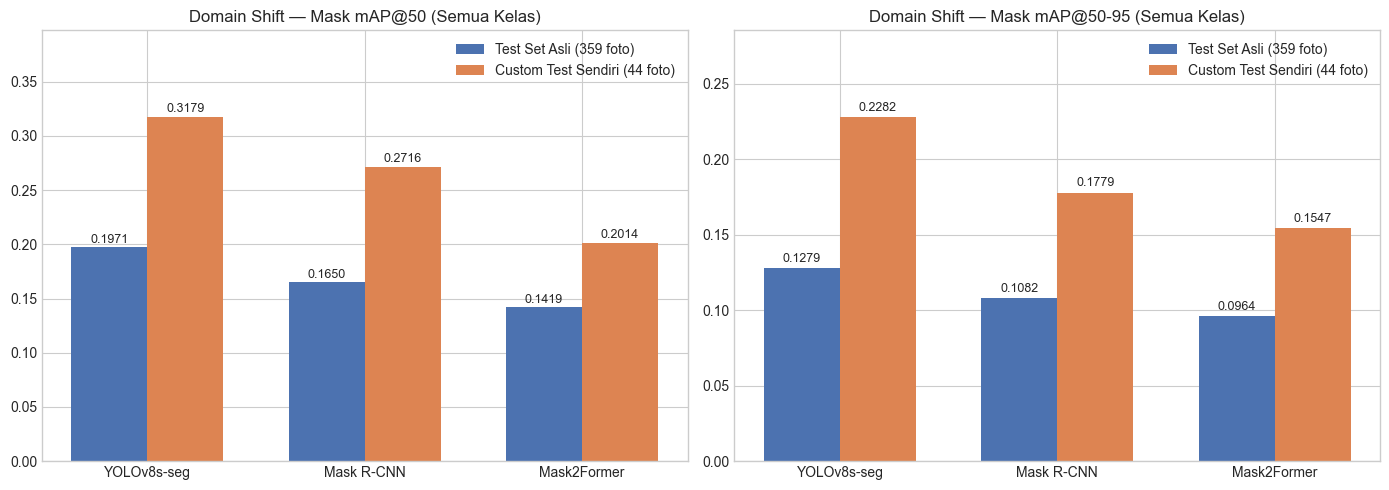

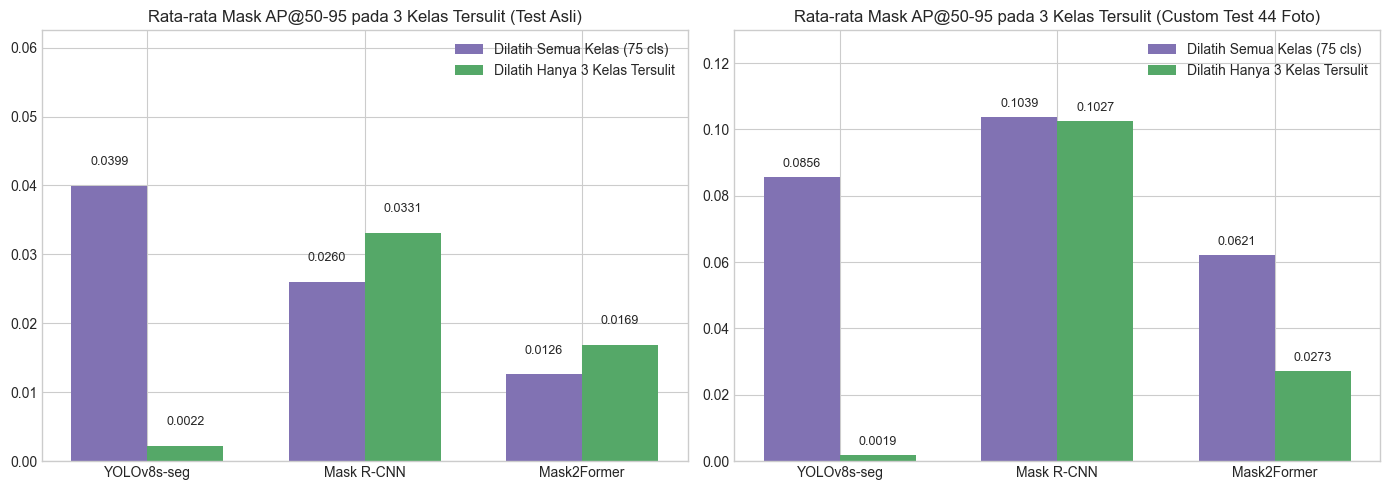

Semua grafik perbandingan tersimpan di: /content/drive/MyDrive/Visi Komputer/Tugas2/tahap2_3kelas_dan_domain_shift/visualizations


In [ ]:
# E1. Tabel & Grafik Perbandingan Lengkap (Apple-to-Apple pada 3 Kelas Tersulit + Domain Shift + Waktu GPU)
def load_3hard_ap(csv_path):
    df = pd.read_csv(csv_path)
    sub = df[df["class_name"].isin(HARD_CLASSES)].set_index("class_name")
    out = {}
    for c in HARD_CLASSES:
        out[f"{c}_ap50"] = float(sub.loc[c, "mask_ap50"]) if c in sub.index and pd.notna(sub.loc[c, "mask_ap50"]) else 0.0
        out[f"{c}_ap50_95"] = float(sub.loc[c, "mask_ap50_95"]) if c in sub.index and pd.notna(sub.loc[c, "mask_ap50_95"]) else 0.0
    out["mean_3hard_ap50"] = round(float(np.mean([out[f"{c}_ap50"] for c in HARD_CLASSES])), 4)
    out["mean_3hard_ap50_95"] = round(float(np.mean([out[f"{c}_ap50_95"] for c in HARD_CLASSES])), 4)
    return out

rows_cmp = []
model_map = [
    ("YOLOv8s-seg", os.path.join(ALL_CLS_DIR, "01_yolov8s_seg", "per_class_ap_test.csv"),
     os.path.join(OUT_DIR, "domain_shift_all_classes", "per_class_ap_yolo_custom.csv"),
     os.path.join(OUT_DIR, "01_yolov8s_seg_3cls", "per_class_ap_orig_test.csv"),
     os.path.join(OUT_DIR, "01_yolov8s_seg_3cls", "per_class_ap_custom_test.csv")),
    ("Mask R-CNN", os.path.join(ALL_CLS_DIR, "02_maskrcnn", "per_class_ap_test.csv"),
     os.path.join(OUT_DIR, "domain_shift_all_classes", "per_class_ap_mrcnn_custom.csv"),
     os.path.join(OUT_DIR, "02_maskrcnn_3cls", "per_class_ap_orig_test.csv"),
     os.path.join(OUT_DIR, "02_maskrcnn_3cls", "per_class_ap_custom_test.csv")),
    ("Mask2Former", os.path.join(ALL_CLS_DIR, "03_mask2former", "per_class_ap_test.csv"),
     os.path.join(OUT_DIR, "domain_shift_all_classes", "per_class_ap_m2f_custom.csv"),
     os.path.join(OUT_DIR, "03_mask2former_3cls", "per_class_ap_orig_test.csv"),
     os.path.join(OUT_DIR, "03_mask2former_3cls", "per_class_ap_custom_test.csv")),
]

for mname, all_orig, all_cust, h3_orig, h3_cust in model_map:
    for scen, sp, path in [
        ("all_classes", "orig_test", all_orig),
        ("all_classes", "custom_test", all_cust),
        ("3_hard_classes", "orig_test", h3_orig),
        ("3_hard_classes", "custom_test", h3_cust),
    ]:
        if os.path.exists(path):
            rows_cmp.append({"model": mname, "scenario": scen, "split": sp, **load_3hard_ap(path)})

df_cmp = pd.DataFrame(rows_cmp)
df_cmp.to_csv(os.path.join(OUT_DIR, "comparison_all_vs_3hard_classes.csv"), index=False)
print("PERBANDINGAN APPLE-TO-APPLE PADA 3 KELAS TERSULIT (SEMUA KELAS VS 3 KELAS SAJA) ")
print(df_cmp[["model", "scenario", "split", "cabinet-merged_ap50_95", "pillow_ap50_95", "wall-tile_ap50_95", "mean_3hard_ap50", "mean_3hard_ap50_95"]].to_string(index=False))

# Rekap Waktu GPU Tahap 1 + Tahap 2
gpu_rows = []
for stage, p in [
    ("Semua Kelas", os.path.join(ALL_CLS_DIR, "01_yolov8s_seg", "gpu_time_log.json")),
    ("Semua Kelas", os.path.join(ALL_CLS_DIR, "02_maskrcnn", "gpu_time_log.json")),
    ("Semua Kelas", os.path.join(ALL_CLS_DIR, "03_mask2former", "gpu_time_log.json")),
    ("3 Kelas Tersulit", os.path.join(OUT_DIR, "01_yolov8s_seg_3cls", "gpu_time_log.json")),
    ("3 Kelas Tersulit", os.path.join(OUT_DIR, "02_maskrcnn_3cls", "gpu_time_log.json")),
    ("3 Kelas Tersulit", os.path.join(OUT_DIR, "03_mask2former_3cls", "gpu_time_log.json")),
]:
    if os.path.exists(p):
        g = json.load(open(p))
        g["stage"] = stage
        gpu_rows.append(g)
df_gpu_all = pd.DataFrame(gpu_rows)
df_gpu_all.to_csv(os.path.join(OUT_DIR, "gpu_time_total_summary.csv"), index=False)
print("\nREKAP WAKTU GPU (TAHAP 1 + TAHAP 2) ")
print(df_gpu_all[["stage", "model", "gpu", "duration_minutes"]].to_string(index=False))

# Plot 1: Grafik Domain Shift (Model Semua Kelas: Test Asli vs Custom Test)
plt.style.use("seaborn-v0_8-whitegrid")
df_ds = pd.read_csv(os.path.join(OUT_DIR, "domain_shift_all_classes", "domain_shift_all_classes.csv"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
models = ["YOLOv8s-seg", "Mask R-CNN", "Mask2Former"]
x = np.arange(len(models))
w = 0.35

for ax, m_orig, m_cust, ttl in [
    (axes[0], "mask_mAP50_orig_test", "mask_mAP50_custom_test", "Domain Shift — Mask mAP@50 (Semua Kelas)"),
    (axes[1], "mask_mAP50_95_orig_test", "mask_mAP50_95_custom_test", "Domain Shift — Mask mAP@50-95 (Semua Kelas)"),
]:
    v1 = [df_ds[df_ds["model"] == m][m_orig].values[0] for m in models]
    v2 = [df_ds[df_ds["model"] == m][m_cust].values[0] for m in models]
    b1 = ax.bar(x - w / 2, v1, w, label="Test Set Asli (359 foto)", color="#4c72b0")
    b2 = ax.bar(x + w / 2, v2, w, label="Custom Test Sendiri (44 foto)", color="#dd8452")
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.004, f"{b.get_height():.4f}", ha="center", fontsize=9, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_title(ttl, fontweight="bold")
    ax.set_ylim(0, max(max(v1), max(v2), 0.05) * 1.25)
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(VIZ_DIR, "domain_shift_all_classes.png"), dpi=200, bbox_inches="tight")
plt.show()

# Plot 2: Perbandingan Semua Kelas vs 3 Kelas Tersulit (Rata-rata AP50-95 pada 3 Kelas Tersulit)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, sp, ttl in [
    (axes[0], "orig_test", "Rata-rata Mask AP@50-95 pada 3 Kelas Tersulit (Test Asli)"),
    (axes[1], "custom_test", "Rata-rata Mask AP@50-95 pada 3 Kelas Tersulit (Custom Test 44 Foto)"),
]:
    sub = df_cmp[df_cmp["split"] == sp]
    v_all = [sub[(sub["model"] == m) & (sub["scenario"] == "all_classes")]["mean_3hard_ap50_95"].values[0] for m in models]
    v_3c = [sub[(sub["model"] == m) & (sub["scenario"] == "3_hard_classes")]["mean_3hard_ap50_95"].values[0] for m in models]
    b1 = ax.bar(x - w / 2, v_all, w, label="Dilatih Semua Kelas (75 cls)", color="#8172b3")
    b2 = ax.bar(x + w / 2, v_3c, w, label="Dilatih Hanya 3 Kelas Tersulit", color="#55a868")
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.003, f"{b.get_height():.4f}", ha="center", fontsize=9, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_title(ttl, fontweight="bold")
    ax.set_ylim(0, max(max(v_all), max(v_3c), 0.05) * 1.25)
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(VIZ_DIR, "comparison_all_vs_3hard_classes.png"), dpi=200, bbox_inches="tight")
plt.show()
print("Semua grafik perbandingan tersimpan di:", VIZ_DIR)

## F: Analisis Kegagalan Berbasis Bukti (5 Foto dari `custom_test_set`)

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

5 FOTO GAGAL TERPILIH UNTUK ANALISIS (HAL. 31) 
 image_id                                                          file_name  n_gt  avg_recall_50  wrong_cls_tot  low_iou_tot  split_tot                                                                 yolo_missed
       13  DATATEST_IMG_7854-21-_JPG.rf.c6555e2e5499a99f6d4f1a2bb2fd2709.jpg     6          0.000              9            1          0                        door-stuff, floor-other-merged, wall-tile, wall-tile
       25  DATATEST_IMG_7854-33-_JPG.rf.132726825c2205f969407dd848ddfc1d.jpg    11          0.061              7            7          0              floor-other-merged, cabinet-merged, plug, wall-tile, wall-tile
       20  DATATEST_IMG_7854-28-_JPG.rf.5c3704c91a3693c9be4c7d4bf90e35a1.jpg    11          0.091              9            4          0                                         stove-merged, sink, pan, towel, cup
       36 DATATEST_IMG_7854-45-_jpeg.rf.2af27e33cfb665385ad80762ca290082.jpg    11          0.121   

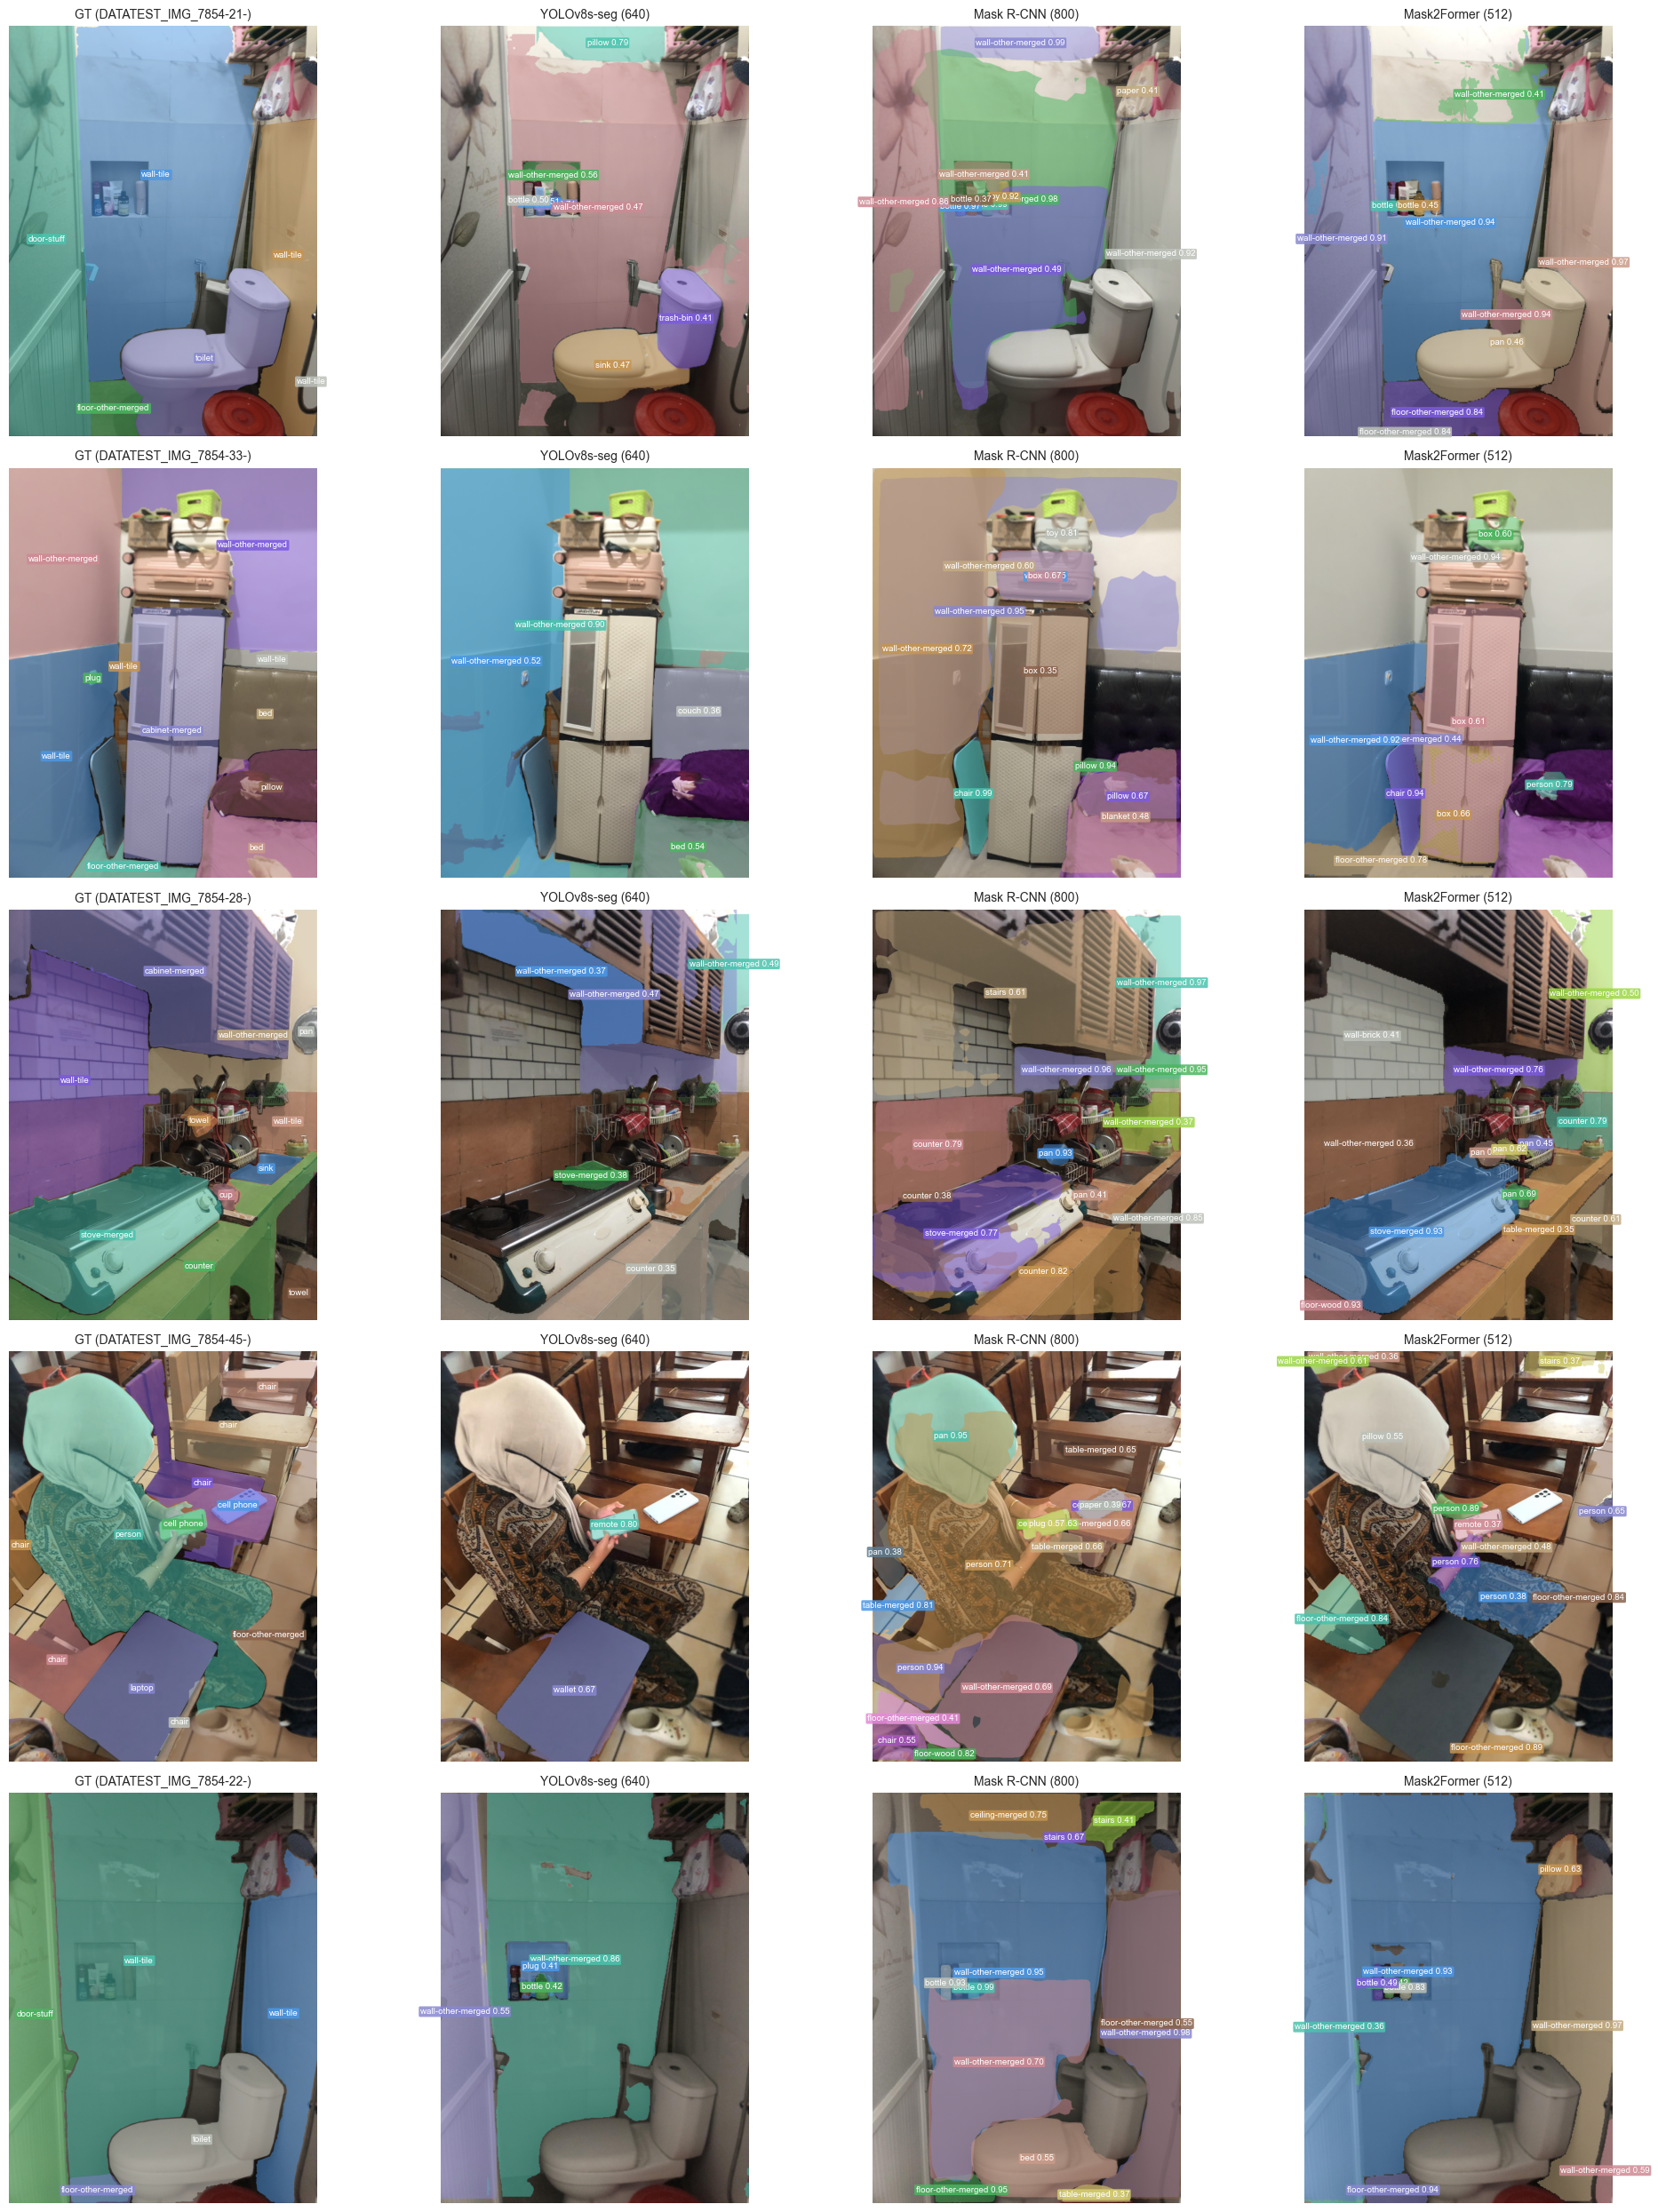

Gambar 5 kasus gagal tersimpan di: /content/drive/MyDrive/Visi Komputer/Tugas2/tahap2_3kelas_dan_domain_shift/failure_analysis


In [ ]:
# F1. Audit Kegagalan pada 44 Foto Custom Test Set & Visualisasi 5 Foto Gagal Terbaik
from ultralytics import YOLO
from transformers import Mask2FormerImageProcessor, Mask2FormerForUniversalSegmentation

coco_custom_dir = os.path.join(CUSTOM_DIR, "coco")
coco_c = COCO(os.path.join(coco_custom_dir, "_annotations.coco.json"))
cat_ids_all = sorted(coco_c.getCatIds())
label2cat_mr = {i + 1: cid for i, cid in enumerate(cat_ids_all)}
label2cat_m2f = {i: cid for i, cid in enumerate(cat_ids_all)}

# Load ketiga model Semua Kelas
yolo_all = YOLO(os.path.join(ALL_CLS_DIR, "01_yolov8s_seg", "train", "weights", "best.pt"))

mr_all = torchvision.models.detection.maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None)
mr_all.roi_heads.box_predictor = FastRCNNPredictor(mr_all.roi_heads.box_predictor.cls_score.in_features, len(cat_ids_all) + 1)
mr_all.roi_heads.mask_predictor = MaskRCNNPredictor(mr_all.roi_heads.mask_predictor.conv5_mask.in_channels, 256, len(cat_ids_all) + 1)
mr_all.load_state_dict(torch.load(os.path.join(ALL_CLS_DIR, "02_maskrcnn", "best_maskrcnn.pth"), map_location=device))
mr_all.to(device).eval()

m2f_dir = os.path.join(ALL_CLS_DIR, "03_mask2former", "best_mask2former")
m2f_proc = Mask2FormerImageProcessor.from_pretrained(m2f_dir)
m2f_all = Mask2FormerForUniversalSegmentation.from_pretrained(m2f_dir).to(device).eval()

def mask_iou(m1, m2):
    inter = np.logical_and(m1, m2).sum()
    union = np.logical_or(m1, m2).sum()
    return float(inter / union) if union > 0 else 0.0

def predict_yolo(model, img_np, w, h, imgsz=640, conf=0.35):
    res = model.predict(img_np, imgsz=imgsz, conf=conf, verbose=False)[0]
    masks, labels, scores = [], [], []
    if res.masks is not None:
        for mk, c, sc in zip(res.masks.data.cpu().numpy(), res.boxes.cls.cpu().numpy(), res.boxes.conf.cpu().numpy()):
            m_rs = np.array(Image.fromarray((mk > 0.5).astype(np.uint8) * 255).resize((w, h), Image.NEAREST)) > 127
            if m_rs.sum() > 0:
                masks.append(m_rs)
                labels.append(model.names[int(c)])
                scores.append(float(sc))
    return masks, labels, scores

@torch.no_grad()
def predict_mrcnn(model, img_pil, conf=0.35, max_eval_side=1333):
    w, h = img_pil.size
    scale = min(1.0, float(max_eval_side) / float(max(w, h)))
    img_in = img_pil.resize((int(round(w * scale)), int(round(h * scale))), Image.BILINEAR) if scale < 1.0 else img_pil
    out = model([F.to_tensor(img_in).to(device)])[0]
    scores_np = out["scores"].cpu().numpy()
    labels_np = out["labels"].cpu().numpy()
    masks_np = out["masks"].cpu().numpy()
    del out
    masks, labels, scores = [], [], []
    for sc, lb, mk in zip(scores_np, labels_np, masks_np):
        if sc >= conf and int(lb) in label2cat_mr:
            bm = (mk[0] > 0.5).astype(np.uint8)
            if bm.sum() == 0:
                continue
            if bm.shape != (h, w):
                bm = np.array(Image.fromarray(bm * 255).resize((w, h), Image.NEAREST)) > 127
            else:
                bm = bm > 0
            masks.append(bm)
            labels.append(coco_c.cats[label2cat_mr[int(lb)]]["name"])
            scores.append(float(sc))
    return masks, labels, scores

@torch.no_grad()
def predict_m2f(model, proc, img_pil, conf=0.35, max_eval_side=1024):
    w, h = img_pil.size
    scale = min(1.0, float(max_eval_side) / float(max(w, h)))
    hs, ws = int(round(h * scale)), int(round(w * scale))
    inp = proc(images=[img_pil], return_tensors="pt")
    out = model(pixel_values=inp["pixel_values"].to(device), pixel_mask=inp["pixel_mask"].to(device))
    res = proc.post_process_instance_segmentation(out, threshold=conf, target_sizes=[(hs, ws)])[0]
    seg = res["segmentation"].cpu().numpy()
    seg_infos = res["segments_info"]
    del out, res
    masks, labels, scores = [], [], []
    for sinfo in seg_infos:
        lbl = int(sinfo["label_id"])
        if lbl in label2cat_m2f:
            bm = (seg == sinfo["id"]).astype(np.uint8)
            if bm.sum() == 0:
                continue
            if bm.shape != (h, w):
                bm = np.array(Image.fromarray(bm * 255).resize((w, h), Image.NEAREST)) > 127
            else:
                bm = bm > 0
            masks.append(bm)
            labels.append(coco_c.cats[label2cat_m2f[lbl]]["name"])
            scores.append(float(sinfo["score"]))
    return masks, labels, scores

def audit_preds_vs_gt(gt_masks, gt_labels, pred_masks, pred_labels):
    matched_50, wrong_cls, low_iou, split_cnt = 0, 0, 0, 0
    best_ious = []
    missed_names = []
    for gm, gl in zip(gt_masks, gt_labels):
        same_ious = [mask_iou(gm, pm) for pm, pl in zip(pred_masks, pred_labels) if pl == gl]
        any_ious = [(mask_iou(gm, pm), pl) for pm, pl in zip(pred_masks, pred_labels)]
        max_same = max(same_ious) if same_ious else 0.0
        best_ious.append(max_same)
        if max_same >= 0.50:
            matched_50 += 1
            if sum(1 for x in same_ious if x >= 0.20) >= 2:
                split_cnt += 1
        elif max_same >= 0.15:
            low_iou += 1  # mask bocor / kasar (IoU < 0.50)
        else:
            # Cek apakah salah kelas atau benar-benar tidak terdeteksi
            best_any = max(any_ious, key=lambda x: x[0]) if any_ious else (0.0, "")
            if best_any[0] >= 0.30 and best_any[1] != gl:
                wrong_cls += 1
            else:
                missed_names.append(gl)
    recall = matched_50 / max(len(gt_masks), 1)
    return {
        "n_gt": len(gt_masks),
        "matched_50": matched_50,
        "recall_50": round(recall, 3),
        "mean_iou": round(float(np.mean(best_ious)) if best_ious else 0.0, 3),
        "missed": len(missed_names),
        "wrong_cls": wrong_cls,
        "low_iou_leak": low_iou,
        "split_obj": split_cnt,
        "missed_classes": ", ".join(missed_names[:5]),
    }

def draw_panel(ax, img_np, masks, labels, scores=None, title=""):
    rng = np.random.default_rng(42)
    overlay = img_np.copy().astype(np.float32)
    texts = []
    for idx, (m, lbl) in enumerate(zip(masks, labels)):
        col = rng.integers(60, 235, size=3, dtype=np.int32)
        if m.sum() == 0:
            continue
        overlay[m] = overlay[m] * 0.5 + col * 0.5
        ys, xs = np.where(m)
        txt = lbl if scores is None else f"{lbl} {scores[idx]:.2f}"
        texts.append((int(np.mean(xs)), int(np.mean(ys)), txt, tuple((col / 255.0).tolist())))
    ax.imshow(overlay.astype(np.uint8))
    for cx, cy, txt, col in texts:
        ax.text(cx, cy, txt, fontsize=7, color="white", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", facecolor=col, alpha=0.85, edgecolor="none"))
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.axis("off")

audit_rows = []
for iid in sorted(coco_c.getImgIds()):
    info = coco_c.loadImgs(iid)[0]
    img_pil = load_coco_aligned_image(os.path.join(coco_custom_dir, info["file_name"]), info)
    img_np = np.array(img_pil)
    w, h = img_pil.size

    gt_masks, gt_labels = [], []
    for a in coco_c.loadAnns(coco_c.getAnnIds(imgIds=iid)):
        m = coco_c.annToMask(a) > 0
        if m.shape == (h, w) and m.sum() > 0:
            gt_masks.append(m)
            gt_labels.append(coco_c.cats[a["category_id"]]["name"])

    ym, yl, ys = predict_yolo(yolo_all, img_np, w, h, imgsz=640, conf=0.35)
    rm, rl, rs = predict_mrcnn(mr_all, img_pil, conf=0.35)
    mm, ml, ms = predict_m2f(m2f_all, m2f_proc, img_pil, conf=0.35)

    ay = audit_preds_vs_gt(gt_masks, gt_labels, ym, yl)
    ar = audit_preds_vs_gt(gt_masks, gt_labels, rm, rl)
    am = audit_preds_vs_gt(gt_masks, gt_labels, mm, ml)

    avg_rec = round((ay["recall_50"] + ar["recall_50"] + am["recall_50"]) / 3, 3)
    audit_rows.append({
        "image_id": iid,
        "file_name": info["file_name"],
        "n_gt": len(gt_masks),
        "avg_recall_50": avg_rec,
        "yolo_rec": ay["recall_50"],
        "mrcnn_rec": ar["recall_50"],
        "m2f_rec": am["recall_50"],
        "wrong_cls_tot": ay["wrong_cls"] + ar["wrong_cls"] + am["wrong_cls"],
        "low_iou_tot": ay["low_iou_leak"] + ar["low_iou_leak"] + am["low_iou_leak"],
        "split_tot": ay["split_obj"] + ar["split_obj"] + am["split_obj"],
        "yolo_missed": ay["missed_classes"],
    })
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

df_audit = pd.DataFrame(audit_rows)
df_audit.to_csv(os.path.join(FAIL_DIR, "custom_failure_audit_44photos.csv"), index=False)

# Pilih 5 foto gagal yang kaya objek (n_gt >= 5) dengan avg_recall_50 terendah / beragam jenis kegagalan
cand_fail = df_audit[df_audit["n_gt"] >= 5].sort_values(["avg_recall_50", "wrong_cls_tot", "low_iou_tot"], ascending=[True, False, False])
top5_ids = cand_fail.head(5)["image_id"].tolist()
print("5 FOTO GAGAL TERPILIH UNTUK ANALISIS (HAL. 31) ")
print(cand_fail.head(10)[["image_id", "file_name", "n_gt", "avg_recall_50", "wrong_cls_tot", "low_iou_tot", "split_tot", "yolo_missed"]].to_string(index=False))

# Muat ulang hanya 5 foto terpilih untuk hemat RAM & render visualisasi 4 panel
cached_data = {}
fig_all, axes_all = plt.subplots(len(top5_ids), 4, figsize=(20, 5 * len(top5_ids)))
for idx, iid in enumerate(top5_ids):
    info = coco_c.loadImgs(iid)[0]
    fn = info["file_name"]
    img_pil = load_coco_aligned_image(os.path.join(coco_custom_dir, fn), info)
    img_np = np.array(img_pil)
    w, h = img_pil.size
    gm, gl = [], []
    for a in coco_c.loadAnns(coco_c.getAnnIds(imgIds=iid)):
        m = coco_c.annToMask(a) > 0
        if m.shape == (h, w) and m.sum() > 0:
            gm.append(m)
            gl.append(coco_c.cats[a["category_id"]]["name"])
    ym, yl, ys = predict_yolo(yolo_all, img_np, w, h, imgsz=640, conf=0.35)
    rm, rl, rs = predict_mrcnn(mr_all, img_pil, conf=0.35)
    mm, ml, ms = predict_m2f(m2f_all, m2f_proc, img_pil, conf=0.35)
    cached_data[iid] = (fn, img_pil, img_np, gm, gl, (ym, yl, ys), (rm, rl, rs), (mm, ml, ms))
    short_fn = fn.split("_JPG")[0].split("_jpeg")[0]

    # Simpan per-case (untuk laporan)
    fig_one, ax_one = plt.subplots(1, 4, figsize=(20, 5))
    for axes_row in [axes_all[idx], ax_one]:
        draw_panel(axes_row[0], img_np, gm, gl, title=f"GT ({short_fn})")
        draw_panel(axes_row[1], img_np, ym, yl, ys, title="YOLOv8s-seg (640)")
        draw_panel(axes_row[2], img_np, rm, rl, rs, title="Mask R-CNN (800)")
        draw_panel(axes_row[3], img_np, mm, ml, ms, title="Mask2Former (512)")
    fig_one.tight_layout()
    fig_one.savefig(os.path.join(FAIL_DIR, f"failure_case_{idx+1}_{short_fn}.png"), dpi=180, bbox_inches="tight")
    plt.close(fig_one)

fig_all.tight_layout()
fig_all.savefig(os.path.join(FAIL_DIR, "failure_5_cases_overview.png"), dpi=180, bbox_inches="tight")
plt.show()
print("Gambar 5 kasus gagal tersimpan di:", FAIL_DIR)

RINGKASAN EKSPERIMEN KECIL A (RATA-RATA PADA 5 FOTO GAGAL) 
                                matched_50  recall_50  mean_iou
model       setting                                            
Mask R-CNN  Baseline_800_c0.35         1.2     0.1310    0.1396
            HighRes_1200_c0.35         1.6     0.1456    0.1450
            LowConf_800_c0.15          1.6     0.1674    0.1788
YOLOv8s-seg Baseline_640_c0.35         0.4     0.0364    0.0506
            HighRes_1280_c0.35         0.4     0.0364    0.0324
            LowConf_640_c0.15          1.2     0.1092    0.1210

RINGKASAN EKSPERIMEN KECIL B (ZOOM-IN / CROP OBJEK GAGAL) 
                image       target_class  yolo_iou_full  yolo_iou_crop  mrcnn_iou_full  mrcnn_iou_crop
DATATEST_IMG_7854-21-         door-stuff         0.0000         0.0000          0.0000          0.0000
DATATEST_IMG_7854-33- floor-other-merged         0.0000         0.2599          0.0000          0.2623
DATATEST_IMG_7854-28-       stove-merged         0.0533    

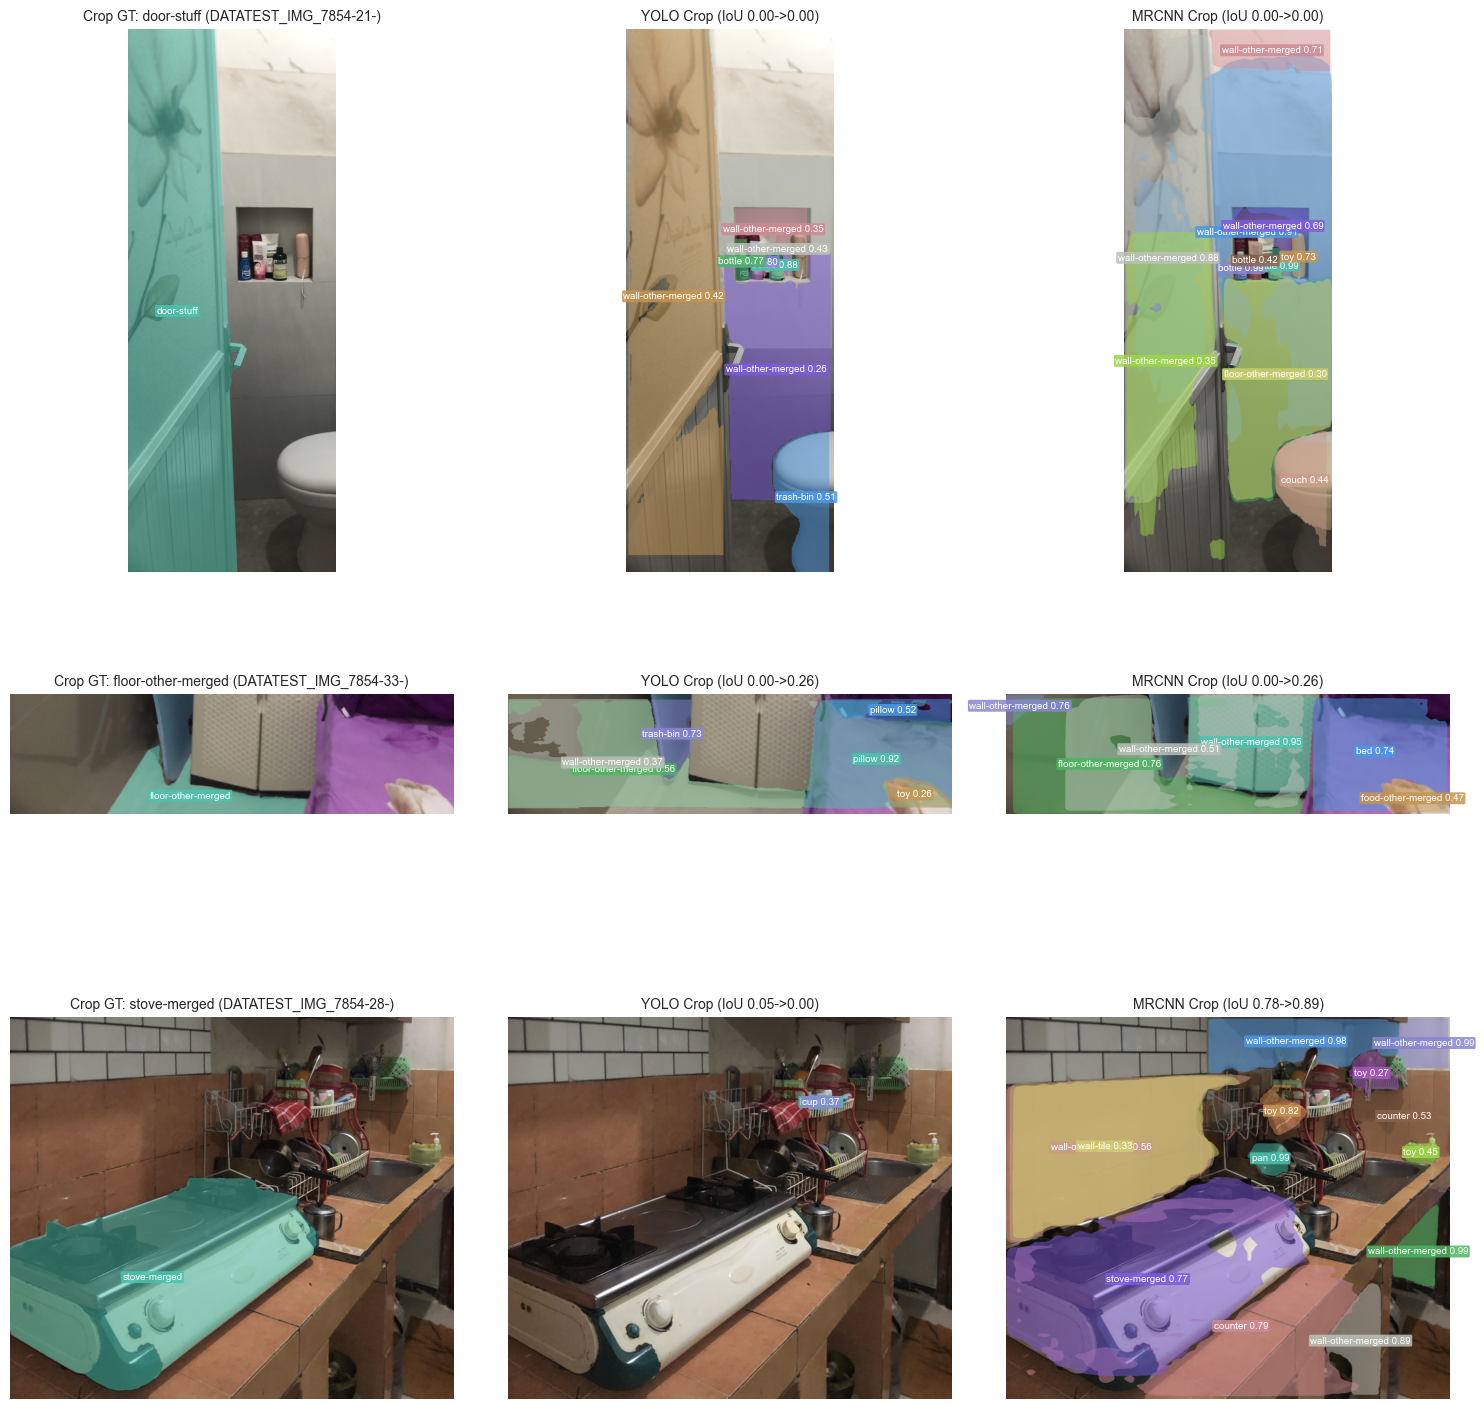


SELESAI! Semua hasil Tahap 2, grafik perbandingan, 5 foto gagal, dan bukti eksperimen kecil tersimpan di: /content/drive/MyDrive/Visi Komputer/Tugas2/tahap2_3kelas_dan_domain_shift


In [ ]:
# F2. Eksperimen Kecil Pembuktian Hipotesis Kegagalan pada 5 Foto Gagal
# Eksperimen A: Uji Resolusi Input (prototype mask YOLO 640->1280 & FPN Mask R-CNN 800->1200) + Confidence Threshold (0.35->0.15)
exp_a_rows = []
for iid in top5_ids:
    fn, img_pil, img_np, gm, gl, _, _, _ = cached_data[iid]
    w, h = img_pil.size
    short_fn = fn.split("_JPG")[0].split("_jpeg")[0]

    # YOLOv8s-seg: Baseline (640, 0.35) vs High-Res (1280, 0.35) vs Low-Conf (640, 0.15)
    for tag, isz, cf in [("Baseline_640_c0.35", 640, 0.35), ("HighRes_1280_c0.35", 1280, 0.35), ("LowConf_640_c0.15", 640, 0.15)]:
        pm, pl, _ = predict_yolo(yolo_all, img_np, w, h, imgsz=isz, conf=cf)
        a = audit_preds_vs_gt(gm, gl, pm, pl)
        exp_a_rows.append({"image": short_fn, "model": "YOLOv8s-seg", "setting": tag, "n_gt": a["n_gt"], "matched_50": a["matched_50"], "recall_50": a["recall_50"], "mean_iou": a["mean_iou"]})

    # Mask R-CNN: Baseline (min=800, 0.35) vs High-Res (min=1200, 0.35) vs Low-Conf (min=800, 0.15)
    for tag, msz, maxsz, cf in [("Baseline_800_c0.35", 800, 1333, 0.35), ("HighRes_1200_c0.35", 1200, 1600, 0.35), ("LowConf_800_c0.15", 800, 1333, 0.15)]:
        mr_all.transform.min_size = (msz,)
        mr_all.transform.max_size = maxsz
        pm, pl, _ = predict_mrcnn(mr_all, img_pil, conf=cf, max_eval_side=maxsz)
        a = audit_preds_vs_gt(gm, gl, pm, pl)
        exp_a_rows.append({"image": short_fn, "model": "Mask R-CNN", "setting": tag, "n_gt": a["n_gt"], "matched_50": a["matched_50"], "recall_50": a["recall_50"], "mean_iou": a["mean_iou"]})

# Kembalikan default transform Mask R-CNN
mr_all.transform.min_size = (800,)
mr_all.transform.max_size = 1333

df_exp_a = pd.DataFrame(exp_a_rows)
df_exp_a.to_csv(os.path.join(FAIL_DIR, "mini_experiment_A_res_and_conf.csv"), index=False)
print("RINGKASAN EKSPERIMEN KECIL A (RATA-RATA PADA 5 FOTO GAGAL) ")
print(df_exp_a.groupby(["model", "setting"])[["matched_50", "recall_50", "mean_iou"]].mean().round(4).to_string())

# Eksperimen B: Uji Zoom-In / Crop pada Objek Gagal Berukuran Kecil/Sedang (menguji hipotesis skala & grid 28x28)
crop_rows = []
fig_crop, axes_crop = plt.subplots(min(3, len(top5_ids)), 3, figsize=(15, 5 * min(3, len(top5_ids))))
if min(3, len(top5_ids)) == 1:
    axes_crop = np.expand_dims(axes_crop, axis=0)

plotted = 0
for iid in top5_ids:
    if plotted >= 3:
        break
    fn, img_pil, img_np, gm, gl, (ym, yl, _), (rm, rl, _), _ = cached_data[iid]
    w, h = img_pil.size
    short_fn = fn.split("_JPG")[0].split("_jpeg")[0]

    # Cari objek GT yang gagal/IoU < 0.50 di Mask R-CNN & ukurannya tidak memenuhi seluruh gambar (< 35% area foto)
    target_obj = None
    for m_gt, lbl_gt in zip(gm, gl):
        area_frac = m_gt.sum() / float(w * h)
        if area_frac > 0.35 or area_frac < 0.002:
            continue
        iou_mr_before = max([mask_iou(m_gt, pm) for pm, pl in zip(rm, rl) if pl == lbl_gt] or [0.0])
        iou_y_before = max([mask_iou(m_gt, pm) for pm, pl in zip(ym, yl) if pl == lbl_gt] or [0.0])
        if iou_mr_before < 0.50 or iou_y_before < 0.50:
            target_obj = (m_gt, lbl_gt, iou_y_before, iou_mr_before)
            break
    if target_obj is None:
        continue

    m_gt, lbl_gt, iou_y_before, iou_mr_before = target_obj
    ys, xs = np.where(m_gt)
    y1, y2, x1, x2 = int(ys.min()), int(ys.max()), int(xs.min()), int(xs.max())
    bw, bh = max(x2 - x1, 20), max(y2 - y1, 20)
    cx1, cy1 = max(0, int(x1 - 0.75 * bw)), max(0, int(y1 - 0.75 * bh))
    cx2, cy2 = min(w, int(x2 + 0.75 * bw)), min(h, int(y2 + 0.75 * bh))

    crop_pil = img_pil.crop((cx1, cy1, cx2, cy2))
    crop_np = np.array(crop_pil)
    cw, ch = crop_pil.size
    gt_crop = m_gt[cy1:cy2, cx1:cx2]

    ym_c, yl_c, ys_c = predict_yolo(yolo_all, crop_np, cw, ch, imgsz=640, conf=0.25)
    rm_c, rl_c, rs_c = predict_mrcnn(mr_all, crop_pil, conf=0.25)

    iou_y_after = max([mask_iou(gt_crop, pm) for pm, pl in zip(ym_c, yl_c) if pl == lbl_gt] or [0.0])
    iou_mr_after = max([mask_iou(gt_crop, pm) for pm, pl in zip(rm_c, rl_c) if pl == lbl_gt] or [0.0])

    crop_rows.append({
        "image": short_fn,
        "target_class": lbl_gt,
        "yolo_iou_full": round(iou_y_before, 4),
        "yolo_iou_crop": round(iou_y_after, 4),
        "mrcnn_iou_full": round(iou_mr_before, 4),
        "mrcnn_iou_crop": round(iou_mr_after, 4),
    })

    draw_panel(axes_crop[plotted, 0], crop_np, [gt_crop], [lbl_gt], title=f"Crop GT: {lbl_gt} ({short_fn})")
    draw_panel(axes_crop[plotted, 1], crop_np, ym_c, yl_c, ys_c, title=f"YOLO Crop (IoU {iou_y_before:.2f}->{iou_y_after:.2f})")
    draw_panel(axes_crop[plotted, 2], crop_np, rm_c, rl_c, rs_c, title=f"MRCNN Crop (IoU {iou_mr_before:.2f}->{iou_mr_after:.2f})")
    plotted += 1

for r in range(plotted, axes_crop.shape[0]):
    for c in range(3):
        axes_crop[r, c].axis("off")

df_exp_b = pd.DataFrame(crop_rows)
df_exp_b.to_csv(os.path.join(FAIL_DIR, "mini_experiment_B_zoom_crop.csv"), index=False)
print("\nRINGKASAN EKSPERIMEN KECIL B (ZOOM-IN / CROP OBJEK GAGAL) ")
print(df_exp_b.to_string(index=False))

fig_crop.tight_layout()
fig_crop.savefig(os.path.join(FAIL_DIR, "mini_experiment_B_zoom_crop.png"), dpi=180, bbox_inches="tight")
plt.show()

del yolo_all, mr_all, m2f_all
free_gpu()
print("\nSELESAI! Semua hasil Tahap 2, grafik perbandingan, 5 foto gagal, dan bukti eksperimen kecil tersimpan di:", OUT_DIR)